# DATA 266 - Homework 11: CLIP Caption-Image Similarity and Zero-Shot CIFAR-10

**Goal.** Use OpenAI's CLIP (`openai/clip-vit-base-patch32`) in two ways, without training anything:

- **Part 1 (5 points): one caption vs. many images.** I compare one text caption with 100 FashionMNIST test images from **each** of the 10 classes (1,000 images). Steps: load CLIP, define the caption, preprocess the images, extract and normalize the embeddings, compute the cosine similarities, show the images with their scores, and write up what I found.
- **Part 2 (5 points): zero-shot classification on CIFAR-10.** I classify all 10,000 CIFAR-10 test images by comparing each image with one text prompt per class, and I report the per-class accuracy and a confusion matrix.

**What I took from the demos:**

- **`Demo_11_CLIP.ipynb`** is the base for both parts. It loads `CLIPModel` and `CLIPProcessor` from `transformers` with the same checkpoint, loads FashionMNIST with `torchvision`, turns the images into PIL images ("the model apparently plays nicer with PIL images than Tensors"), builds prompts like `"an image of a {class}"`, gets `logits_per_image`, applies a softmax, and plots one image's class probabilities as a bar chart. I reused all of that. The difference is that I call `get_image_features` / `get_text_features` separately and normalize the embeddings myself, because Part 1 asks for that step explicitly. It also means each image is encoded only once, instead of once per caption.
- **`Demo_11_Knowledge_Distillation.ipynb`** gave me the CIFAR-10 part: `datasets.CIFAR10(root='./data', train=False, download=True)`, the automatic device choice, and the batched evaluation loop with `torch.no_grad()` from its `test()` function. I didn't use its normalization transform, because CLIP needs its own preprocessing (see Section 9). The demo's CNNs are useful for comparison: its teacher network got **73.06%** on the CIFAR-10 test set after 10 epochs of supervised training, and CLIP here sees no CIFAR-10 training image at all.

**Small changes from the CLIP demo:**

- The demo resizes FashionMNIST to 64×64 first. I give CLIP the original 28×28 images, because `CLIPProcessor` resizes everything to 224×224 anyway, and resizing twice only adds blur.
- The demo's processor gets a one-channel grayscale image. I convert it to 3-channel RGB first (the same gray values in R, G and B), which is the format CLIP was trained on.

## 1. Personal Parameters

Same formulas as in my earlier assignments. The assert checks the values.

- **CLS_A = 6** picks the caption for Part 1. In FashionMNIST class 6 is **Shirt**, so the caption is about a shirt. That turned out to be a good test, because "Shirt" is the class that looks most like other classes (T-shirt/top, Pullover, Coat).
- **CLS_B = 0** (T-shirt/top) is the class I watch most closely in Part 1, since it's the most likely to be mixed up with the caption.
- **SLICE** picks the images: for each class I take the first 100 FashionMNIST test images at index SLICE or later. In Part 2 SLICE is the start of the example images I show (all 10,000 test images are evaluated).
- **SEED** seeds Python, NumPy and PyTorch. Nothing random is trained here, so it only matters for the random example picks.
- **HP_ID** is only reported.

In [1]:
SID4 = 9486
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

assert (SEED, SLICE, HP_ID, CLS_A, CLS_B) == (9486, 486, 0, 6, 0)

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")

SID4  = 9486
SEED  = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0


## 2. Package Setup

The demo only needs `torch`, `torchvision`, `transformers` and `matplotlib`. I also use `scikit-learn` for the ROC AUC and the confusion matrix, and `pandas` for the tables. Packages are only installed if they're missing, so an existing torch setup isn't upgraded by accident.

In [2]:
import importlib.util
import subprocess
import sys

needed = {"torch": "torch", "torchvision": "torchvision", "transformers": "transformers",
          "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib"}
missing = [pip_name for module, pip_name in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    print("installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("all packages are already installed")

all packages are already installed


## 3. Imports, Settings and Reproducibility

In [3]:
import os
import json
import random
import time
import textwrap
import warnings
from datetime import datetime, timezone

# torch has to be imported before scikit-learn on my Mac: with sklearn first, two OpenMP runtimes get loaded
# and the CLIP forward pass crashes the kernel with a segmentation fault (see RUN_LOG.txt)
import torch
import torchvision
import transformers
from torchvision import datasets
from transformers import CLIPModel, CLIPProcessor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import confusion_matrix, roc_auc_score
from tqdm.auto import tqdm  # for progress bar

transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)

# chart colours (reference palette): one blue for single series and the sequential ramp,
# orange as the second series, neutral gray for "everything else", neutral ink for text
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a8a7a2"
INK, INK_2 = "#0b0b0b", "#52514e"
BLUE_RAMP = ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.constrained_layout.use": True, "figure.dpi": 110, "axes.edgecolor": "#d6d5d0",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.titlecolor": INK, "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})

W1117 11:12:43.391000 42802 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


### Experiment settings

- **`N_PER_CLASS = 100`**: the assignment asks for at least 100 images of each class in Part 1.
- **`PROMPT_TEMPLATE = "a photo of a {}."`**: the standard CLIP prompt, used for the Part 1 caption and the main Part 2 classifier. In Part 2 I also try the demo's `"an image of a {}"` and an average over 8 prompt templates, to see how much the wording matters.
- **`BATCH_SIZE = 128`** images per forward pass.
- **Smoke test.** `HW11_SMOKE_TEST=1` uses 10 images per class in Part 1 and 500 CIFAR-10 images in Part 2, only to check that every cell runs. It's off by default.

In [4]:
SMOKE_TEST = os.environ.get("HW11_SMOKE_TEST", "0") == "1"

MODEL_NAME = "openai/clip-vit-base-patch32"   # same checkpoint as Demo_11_CLIP
PROMPT_TEMPLATE = "a photo of a {}."
DEMO_TEMPLATE = "an image of a {}"             # the prompt used in Demo_11_CLIP
ENSEMBLE_TEMPLATES = [                         # a few of the CIFAR-10 templates from the CLIP paper's repository
    "a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.", "a photo of the small {}.",
    "a pixelated photo of a {}.", "a close-up photo of a {}.", "a good photo of a {}.", "a photo of the {}.",
]
N_PER_CLASS = 100
CIFAR_LIMIT = None      # None = all 10,000 test images
BATCH_SIZE = 128
N_SHOW = 16             # images in the top / bottom grids

if SMOKE_TEST:
    N_PER_CLASS = 10
    CIFAR_LIMIT = 500

for folder in ["figures", "results", "cache"]:
    os.makedirs(folder, exist_ok=True)
SUFFIX = "_smoke" if SMOKE_TEST else ""
LOG_PATH = f"results/run_log_raw{SUFFIX}.txt"
open(LOG_PATH, "w").close()


def log(*args):
    stamp = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    line = f"[{stamp}] " + " ".join(str(a) for a in args)
    print(line)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def get_device():
    # same idea as the distillation demo (torch.accelerator), written out so it also works on older torch versions
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


set_seed(SEED)
device = os.environ.get("HW11_DEVICE") or get_device()
device_name = {"cuda": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "",
               "mps": "Apple GPU (MPS)", "cpu": "CPU only"}[device]
RUN_START = time.time()
log("device:", device, "|", device_name, "| smoke test:", SMOKE_TEST)
log("python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__,
    "| transformers", transformers.__version__, "| scikit-learn", sklearn.__version__)

[2026-11-17T19:12:45Z] device: mps | Apple GPU (MPS) | smoke test: False
[2026-11-17T19:12:45Z] python 3.13.9 | torch 2.14.0 | torchvision 0.29.0 | transformers 5.21.0 | scikit-learn 1.7.2


## 4. Load the CLIP Model

Same as the demo: `CLIPModel` and `CLIPProcessor` from `openai/clip-vit-base-patch32`. CLIP has two encoders that were trained together on 400 million (image, text) pairs from the internet:

- an **image encoder**, a Vision Transformer (ViT-B/32) that cuts a 224×224 image into 7×7 = 49 patches of 32×32 pixels,
- a **text encoder**, a 12-layer Transformer over at most 77 tokens.

Each encoder ends with a linear projection into the **same 512-dimensional space**. Training pushed the embedding of an image close to the embedding of its own caption and away from the other captions in the batch (a contrastive loss). That shared space is why an image and a sentence can be compared directly.

The model is only used for inference, so it's put in `eval()` mode and all gradients are off.

In [5]:
t0 = time.time()
model = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
for p in model.parameters():
    p.requires_grad_(False)

n_vision = sum(p.numel() for p in model.vision_model.parameters()) + model.visual_projection.weight.numel()
n_text = sum(p.numel() for p in model.text_model.parameters()) + model.text_projection.weight.numel()
log(f"loaded {MODEL_NAME} in {time.time() - t0:.1f}s on {device}")
log(f"parameters: total {sum(p.numel() for p in model.parameters()):,} | image side {n_vision:,} | text side {n_text:,}")
log(f"embedding dim {model.config.projection_dim} | image size {processor.image_processor.crop_size} | "
    f"logit scale exp(t) = {model.logit_scale.exp().item():.2f}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[2026-11-17T19:12:48Z] loaded openai/clip-vit-base-patch32 in 3.3s on mps
[2026-11-17T19:12:48Z] parameters: total 151,277,313 | image side 87,849,216 | text side 63,428,096


[2026-11-17T19:12:50Z] embedding dim 512 | image size SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | logit scale exp(t) = 100.00


### Helper functions: extract and normalize the embeddings

The demo runs `model(**inputs)` with the images and the texts together and reads `outputs.logits_per_image`. Inside, CLIP does three things: it encodes the image, encodes the texts, and computes `logit_scale × cosine similarity`. I do these steps one by one:

1. `processor(images=...)` resizes the shorter side to 224 (bicubic), center-crops to 224×224, scales to [0, 1] and normalizes with CLIP's own channel mean and std.
2. `model.get_image_features(...)` / `model.get_text_features(...)` give the 512-d projected embeddings. In transformers 5 these functions return an output object, and the projected embedding is its `pooler_output`. Older versions return the tensor directly, and the helper handles both.
3. **L2 normalization**: every embedding is divided by its length. After that, the dot product of an image and a text embedding *is* their cosine similarity, a number between −1 and 1.

The check at the end confirms that my step-by-step version gives exactly the same logits as the demo's `model(**inputs).logits_per_image`.

In [6]:
def _as_tensor(out):
    return out if torch.is_tensor(out) else out.pooler_output


@torch.no_grad()
def encode_images(pil_images, batch_size=BATCH_SIZE, desc="images"):
    feats = []
    for i in tqdm(range(0, len(pil_images), batch_size), desc=desc, leave=False):
        pixel_values = processor(images=pil_images[i:i + batch_size], return_tensors="pt")["pixel_values"].to(device)
        feats.append(_as_tensor(model.get_image_features(pixel_values=pixel_values)).float().cpu())
    return torch.nn.functional.normalize(torch.cat(feats), dim=-1)


@torch.no_grad()
def encode_texts(texts):
    tokens = processor(text=texts, return_tensors="pt", padding=True).to(device)
    return torch.nn.functional.normalize(_as_tensor(model.get_text_features(**tokens)).float().cpu(), dim=-1)


# check against the demo's one-shot forward pass on two images and two texts
from PIL import Image
_imgs = [Image.new("RGB", (32, 32), (200, 30, 30)), Image.new("RGB", (32, 32), (30, 30, 200))]
_texts = ["a photo of a red square", "a photo of a blue square"]
with torch.no_grad():
    demo_logits = model(**processor(text=_texts, images=_imgs, return_tensors="pt", padding=True).to(device)).logits_per_image.cpu()
my_logits = model.logit_scale.exp().item() * encode_images(_imgs, desc="check") @ encode_texts(_texts).T
print("demo logits:\n", demo_logits.numpy().round(3))
print("my logits:\n", my_logits.numpy().round(3))
assert torch.allclose(demo_logits, my_logits, atol=1e-3)
print("same as model(**inputs).logits_per_image")

check:   0%|          | 0/1 [00:00<?, ?it/s]

demo logits:
 [[27.277 22.241]
 [24.28  29.603]]
my logits:
 [[27.277 22.241]
 [24.28  29.603]]
same as model(**inputs).logits_per_image


# Part 1: One Caption vs. Many Images

## 5. Load FashionMNIST and Pick 100 Images per Class

Same dataset as the CLIP demo (`FashionMNIST(root='data', train=False, download=True)`), but without the demo's transform, because `CLIPProcessor` does all the preprocessing. For each of the 10 classes I take the **first 100 test images at index SLICE (486) or later**, which gives 1,000 images in total. The test set has 1,000 images per class, so there are always enough.

In [7]:
fmnist = datasets.FashionMNIST(root="data", train=False, download=True)
class_names = fmnist.classes
labels_all = fmnist.targets.numpy()

part1_idx = []
for c in range(len(class_names)):
    candidates = np.where((labels_all == c) & (np.arange(len(labels_all)) >= SLICE))[0]
    part1_idx.extend(candidates[:N_PER_CLASS].tolist())
part1_idx = np.array(part1_idx)
part1_labels = labels_all[part1_idx]

counts = pd.Series(part1_labels).value_counts().sort_index()
assert (counts == N_PER_CLASS).all() and len(counts) == 10
log(f"FashionMNIST test: {len(fmnist)} images | Part 1 set: {len(part1_idx)} images, {N_PER_CLASS} per class, "
    f"indices {part1_idx.min()}-{part1_idx.max()}")
print(pd.DataFrame({"class": class_names, "images": counts.values,
                    "first index": [part1_idx[part1_labels == c].min() for c in range(10)],
                    "last index": [part1_idx[part1_labels == c].max() for c in range(10)]}).to_string())

[2026-11-17T19:12:50Z] FashionMNIST test: 10000 images | Part 1 set: 1000 images, 100 per class, indices 486-1594
         class  images  first index  last index
0  T-shirt/top     100          488        1494
1      Trouser     100          487        1499
2     Pullover     100          497        1477
3        Dress     100          490        1570
4         Coat     100          491        1304
5       Sandal     100          502        1439
6        Shirt     100          512        1487
7      Sneaker     100          494        1534
8          Bag     100          486        1521
9   Ankle boot     100          493        1594


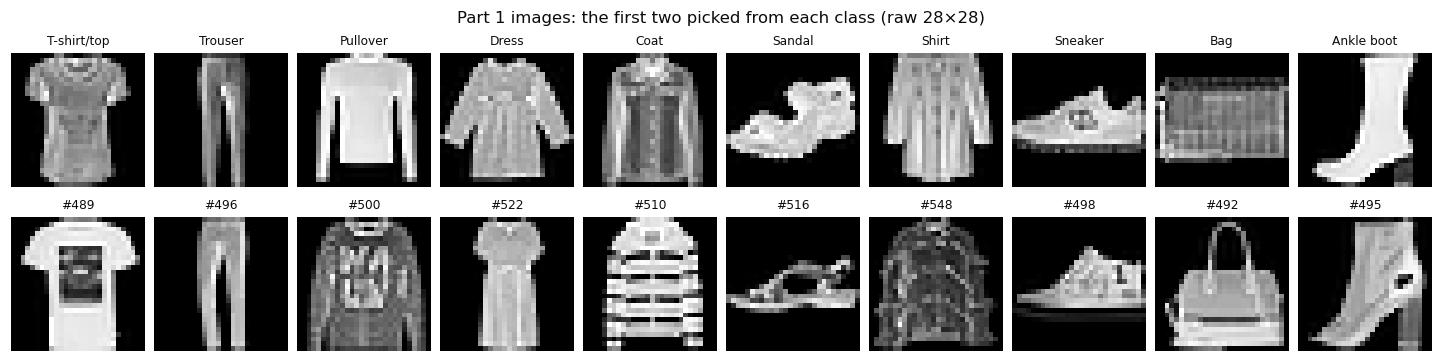

In [8]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for c in range(10):
    for r in range(2):
        i = part1_idx[part1_labels == c][r]
        axes[r, c].imshow(fmnist.data[i], cmap="gray")
        axes[r, c].set_title(class_names[c] if r == 0 else f"#{i}", fontsize=8)
        axes[r, c].axis("off")
fig.suptitle("Part 1 images: the first two picked from each class (raw 28×28)")
plt.savefig("figures/part1_examples.png", dpi=130)
plt.show()

## 6. Define the Caption

The caption comes from my personal parameter CLS_A = 6, so it's about a **shirt**. I use the standard CLIP prompt wording `"a photo of a {}."` with the class name in lowercase.

In [9]:
CAPTION = PROMPT_TEMPLATE.format(class_names[CLS_A].lower())
TARGET = CLS_A
print("caption:", repr(CAPTION))
print("matching class:", TARGET, class_names[TARGET], "| class to watch (CLS_B):", CLS_B, class_names[CLS_B])
print("tokens:", processor.tokenizer.tokenize(CAPTION))

caption: 'a photo of a shirt.'
matching class: 6 Shirt | class to watch (CLS_B): 0 T-shirt/top
tokens: ['a</w>', 'photo</w>', 'of</w>', 'a</w>', 'shirt</w>', '.</w>']


## 7. Preprocess the Images

Each image goes through:

1. `PIL.Image.fromarray(uint8 28×28)` → `.convert("RGB")`, so the gray value is copied into 3 channels.
2. `CLIPProcessor`: bicubic resize to 224×224 (the shorter side, then a center crop, which does nothing for square images), scale to [0, 1], normalize each channel with CLIP's mean (0.481, 0.458, 0.408) and std (0.269, 0.261, 0.276).

So a 28×28 FashionMNIST image is blown up 8× before CLIP sees it. The images are tiny, blurry, gray clothes on a black background, which is very different from the internet photos CLIP was trained on. I expect that to lower the scores overall.

one raw image: (28, 28) RGB
after CLIPProcessor: (1, 3, 224, 224) | min -1.792 | max 2.146
image mean/std used: (0.48145466, 0.4578275, 0.40821073) (0.26862954, 0.26130258, 0.27577711)


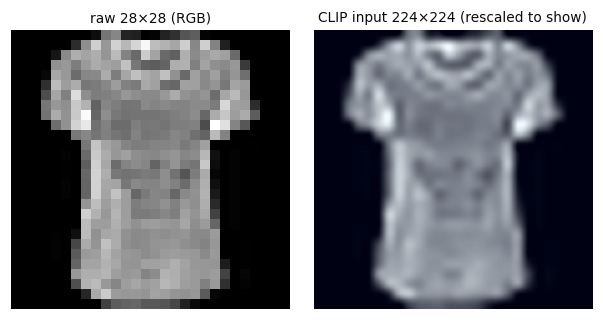

In [10]:
part1_pil = [Image.fromarray(fmnist.data[i].numpy()).convert("RGB") for i in part1_idx]
example = processor(images=part1_pil[:1], return_tensors="pt")["pixel_values"]
print("one raw image:", part1_pil[0].size, part1_pil[0].mode)
print("after CLIPProcessor:", tuple(example.shape), "| min", round(example.min().item(), 3), "| max", round(example.max().item(), 3))
print("image mean/std used:", processor.image_processor.image_mean, processor.image_processor.image_std)

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8))
axes[0].imshow(part1_pil[0]); axes[0].set_title("raw 28×28 (RGB)", fontsize=9)
shown = example[0].permute(1, 2, 0).numpy()
axes[1].imshow((shown - shown.min()) / (shown.max() - shown.min())); axes[1].set_title("CLIP input 224×224 (rescaled to show)", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

## 8. Extract and Normalize the Embeddings, then Compute the Similarities

The 1,000 images are encoded in batches of 128 and the caption once. After L2 normalization every embedding has length 1, so

**similarity(image, caption) = image_embedding · caption_embedding = cos θ.**

I also report CLIP's own logit, `100 × cos θ` (the learned temperature is exp(t) = 100), because that's the number the demo's `logits_per_image` shows.

In [11]:
t0 = time.time()
img_emb = encode_images(part1_pil, desc="FashionMNIST")
cap_emb = encode_texts([CAPTION])
log(f"encoded {len(part1_pil)} images in {time.time() - t0:.1f}s | image embeddings {tuple(img_emb.shape)} | caption {tuple(cap_emb.shape)}")
print("norms after normalization: images", img_emb.norm(dim=-1).min().item(), "-", img_emb.norm(dim=-1).max().item(),
      "| caption", cap_emb.norm(dim=-1).item())

sim = (img_emb @ cap_emb.T).squeeze(1).numpy()           # cosine similarity
LOGIT_SCALE = model.logit_scale.exp().item()
part1 = pd.DataFrame({"dataset_index": part1_idx, "label": part1_labels,
                      "class": [class_names[c] for c in part1_labels],
                      "cosine": sim, "clip_logit": LOGIT_SCALE * sim})
part1["is_target"] = part1.label == TARGET
part1["rank"] = part1.cosine.rank(ascending=False, method="first").astype(int)
print(part1.sort_values("rank").head(10).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

FashionMNIST:   0%|          | 0/8 [00:00<?, ?it/s]

[2026-11-17T19:13:06Z] encoded 1000 images in 14.8s | image embeddings (1000, 512) | caption (1, 512)
norms after normalization: images 0.9999995827674866 - 1.0000003576278687 | caption 0.9999999403953552
 dataset_index  label       class  cosine  clip_logit  is_target  rank
          1049      0 T-shirt/top  0.2859     28.5906      False     1
           605      0 T-shirt/top  0.2841     28.4064      False     2
           761      6       Shirt  0.2830     28.2954       True     3
           954      0 T-shirt/top  0.2823     28.2315      False     4
           633      6       Shirt  0.2821     28.2139       True     5
          1450      0 T-shirt/top  0.2818     28.1759      False     6
          1252      0 T-shirt/top  0.2816     28.1562      False     7
          1000      0 T-shirt/top  0.2788     27.8809      False     8
          1052      0 T-shirt/top  0.2784     27.8377      False     9
           677      0 T-shirt/top  0.2777     27.7676      False    10


In [12]:
per_class = (part1.groupby("class")["cosine"].agg(["mean", "std", "min", "median", "max"])
             .reindex(class_names).sort_values("mean", ascending=False))
per_class["in top 100"] = part1[part1["rank"] <= N_PER_CLASS].groupby("class").size().reindex(per_class.index).fillna(0).astype(int)
per_class["mean rank"] = part1.groupby("class")["rank"].mean().reindex(per_class.index).round(1)
print(f"Cosine similarity with {CAPTION!r}, per class ({N_PER_CLASS} images each), sorted by mean:\n")
print(per_class.to_string(float_format=lambda x: f"{x:.4f}"))

auc = roc_auc_score(part1.is_target, part1.cosine)
top_k = part1[part1["rank"] <= N_PER_CLASS]
p_at_100 = top_k.is_target.mean()
auc_vs_b = roc_auc_score(part1[part1.label.isin([TARGET, CLS_B])].is_target,
                         part1[part1.label.isin([TARGET, CLS_B])].cosine)
print(f"\nROC AUC, {class_names[TARGET]} vs. all other classes: {auc:.3f}")
print(f"ROC AUC, {class_names[TARGET]} vs. {class_names[CLS_B]} only:   {auc_vs_b:.3f}")
print(f"Precision of the top {N_PER_CLASS} images by similarity (share that are really {class_names[TARGET]}): {p_at_100:.2f}")
print(f"Range of all cosine scores: {part1.cosine.min():.4f} to {part1.cosine.max():.4f} "
      f"(spread {part1.cosine.max() - part1.cosine.min():.4f})")

Cosine similarity with 'a photo of a shirt.', per class (100 images each), sorted by mean:

              mean    std    min  median    max  in top 100  mean rank
class                                                                 
T-shirt/top 0.2552 0.0202 0.1993  0.2611 0.2859          49   180.0000
Shirt       0.2525 0.0171 0.2018  0.2547 0.2830          37   194.6000
Pullover    0.2457 0.0134 0.1883  0.2479 0.2718           9   246.2000
Coat        0.2389 0.0132 0.2105  0.2397 0.2693           2   314.2000
Dress       0.2268 0.0138 0.1955  0.2258 0.2739           3   449.2000
Trouser     0.2235 0.0078 0.1941  0.2247 0.2386           0   481.8000
Bag         0.2126 0.0087 0.1941  0.2119 0.2359           0   621.0000
Sandal      0.1986 0.0092 0.1727  0.2000 0.2160           0   786.2000
Sneaker     0.1929 0.0083 0.1702  0.1924 0.2173           0   853.8000
Ankle boot  0.1905 0.0086 0.1715  0.1908 0.2113           0   877.9000

ROC AUC, Shirt vs. all other classes: 0.840
ROC AUC, Sh

## 9. Visualize the Results

Four views:

1. **The 16 most similar images** to the caption, with their cosine score and true class.
2. **The 16 least similar images.**
3. **5 images from every class with their scores**, so each class shows up next to its numbers (the first 5 of the 100 picked per class).
4. **The score distribution per class**, every image as a dot. The matching class is in blue and the rest in gray, and the dashed line is the mean over all 1,000 images.

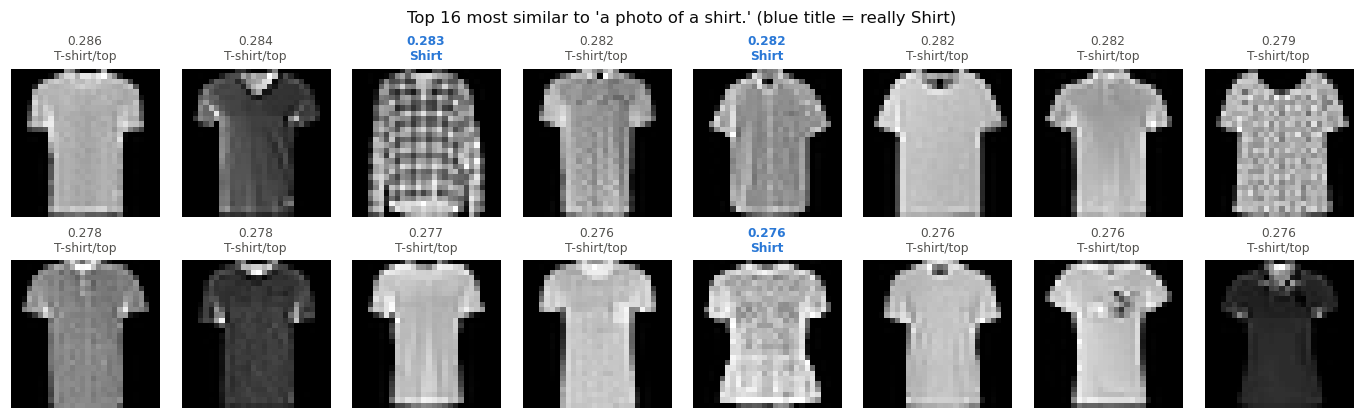

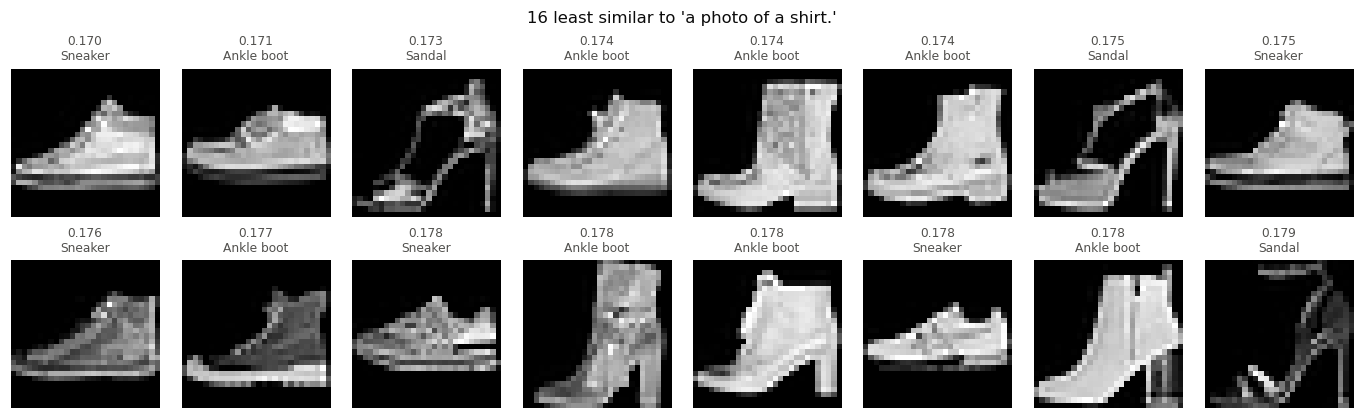

In [13]:
def image_grid(rows, title, path, ncols=8):
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.55 * ncols, 1.85 * nrows))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        ax.imshow(fmnist.data[r.dataset_index], cmap="gray")
        ax.set_title(f"{r.cosine:.3f}\n{r['class']}", fontsize=8,
                     color=BLUE if r.is_target else INK_2, fontweight="bold" if r.is_target else "normal")
    fig.suptitle(title)
    plt.savefig(path, dpi=130)
    plt.show()


ordered = part1.sort_values("rank")
image_grid(ordered.head(N_SHOW), f"Top {N_SHOW} most similar to {CAPTION!r} (blue title = really {class_names[TARGET]})",
           "figures/part1_top16.png")
image_grid(ordered.tail(N_SHOW).iloc[::-1], f"{N_SHOW} least similar to {CAPTION!r}", "figures/part1_bottom16.png")

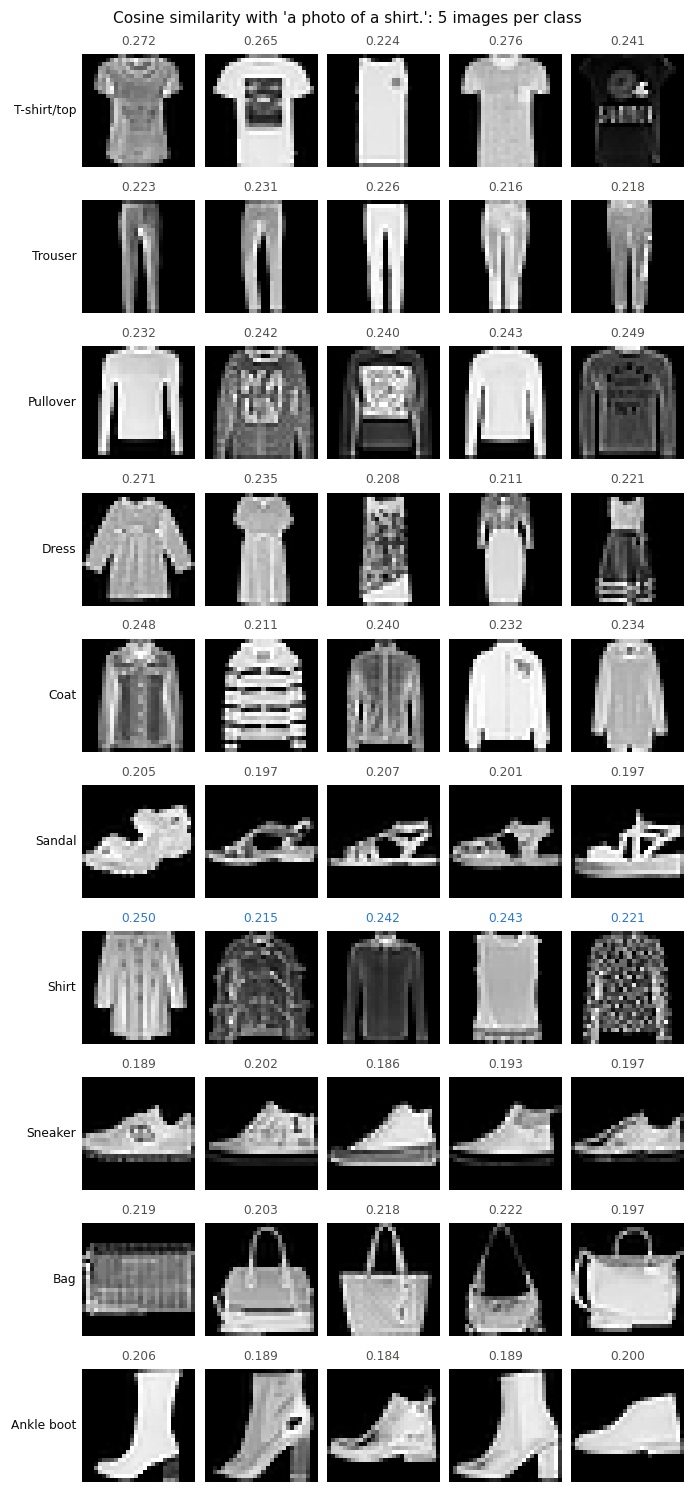

In [14]:
fig, axes = plt.subplots(10, 5, figsize=(6.2, 13.5))
for c in range(10):
    rows = part1[part1.label == c].head(5)
    for j, (_, r) in enumerate(rows.iterrows()):
        ax = axes[c, j]
        ax.imshow(fmnist.data[r.dataset_index], cmap="gray")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(f"{r.cosine:.3f}", fontsize=8, color=BLUE if c == TARGET else INK_2)
        if j == 0:
            ax.set_ylabel(class_names[c], fontsize=8, rotation=0, ha="right", va="center", color=INK)
fig.suptitle(f"Cosine similarity with {CAPTION!r}: 5 images per class", fontsize=10)
plt.savefig("figures/part1_per_class_examples.png", dpi=130)
plt.show()

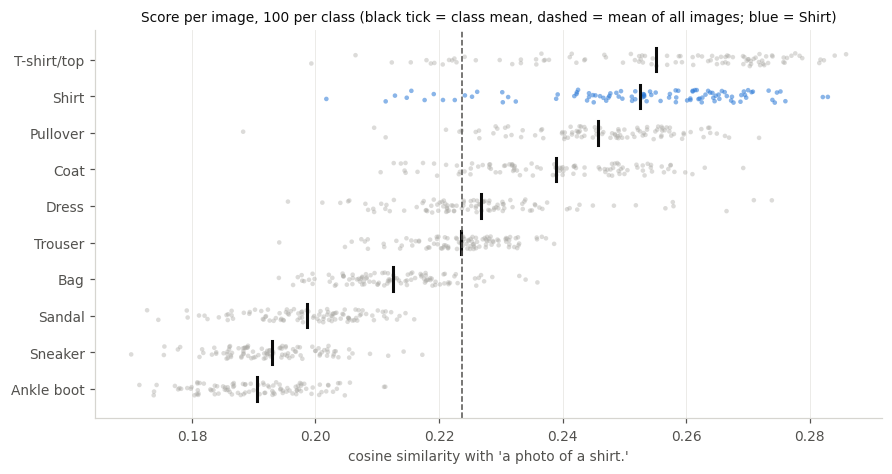

In [15]:
order = per_class.index.tolist()
fig, ax = plt.subplots(figsize=(8, 4.2))
rng = np.random.default_rng(SEED)
for y, name in enumerate(order):
    vals = part1[part1["class"] == name].cosine.values
    is_t = name == class_names[TARGET]
    ax.scatter(vals, y + rng.uniform(-0.18, 0.18, len(vals)), s=9, alpha=0.55 if is_t else 0.4,
               color=BLUE if is_t else GRAY, edgecolors="none")
    ax.plot([np.mean(vals)] * 2, [y - 0.32, y + 0.32], color=INK, linewidth=2)
ax.axvline(part1.cosine.mean(), color=INK_2, linestyle="--", linewidth=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"cosine similarity with {CAPTION!r}")
ax.set_title(f"Score per image, {N_PER_CLASS} per class (black tick = class mean, dashed = mean of all images; "
             f"blue = {class_names[TARGET]})", fontsize=9)
plt.savefig("figures/part1_similarity_by_class.png", dpi=130)
plt.show()

### Extra check: is this a problem with the shirt caption, or with CLIP on FashionMNIST in general?

To see whether the result above is specific to "shirt", I ran the same test with a caption for **every** class (`"a photo of a {class}."`) on the same 1,000 image embeddings. For each caption I report the ROC AUC (how well the score separates its own class from the other 9) and how many of the top 100 images really belong to that class. The image embeddings are reused, so this costs only 10 extra text encodings.

In [16]:
all_caps = [PROMPT_TEMPLATE.format(c.lower()) for c in class_names]
all_sims = (img_emb @ encode_texts(all_caps).T).numpy()
rows = []
for c, cap in enumerate(all_caps):
    s = all_sims[:, c]
    top = np.argsort(-s)[:N_PER_CLASS]
    rows.append({"caption": cap, "class": class_names[c], "AUC (own class vs rest)": roc_auc_score(part1_labels == c, s),
                 f"own class in top {N_PER_CLASS}": (part1_labels[top] == c).mean(),
                 "mean cos own class": s[part1_labels == c].mean(), "mean cos other classes": s[part1_labels != c].mean()})
caption_table = pd.DataFrame(rows).sort_values("AUC (own class vs rest)", ascending=False)
print(caption_table.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

                  caption       class  AUC (own class vs rest)  own class in top 100  mean cos own class  mean cos other classes
 a photo of a ankle boot.  Ankle boot                    0.992                 0.890               0.278                   0.217
    a photo of a trouser.     Trouser                    0.975                 0.830               0.275                   0.231
    a photo of a sneaker.     Sneaker                    0.960                 0.650               0.274                   0.224
        a photo of a bag.         Bag                    0.939                 0.700               0.266                   0.225
       a photo of a coat.        Coat                    0.918                 0.480               0.265                   0.228
   a photo of a pullover.    Pullover                    0.906                 0.510               0.295                   0.248
      a photo of a dress.       Dress                    0.897                 0.500             

## 10. Findings for Part 1

All numbers are from the outputs above: caption `'a photo of a shirt.'`, 1,000 FashionMNIST test images (100 per class).

**1. The similarity scores are small and close together.** Every cosine similarity is between **0.170 and 0.286**, a spread of only 0.116, and none is negative. That's normal for CLIP: image and text embeddings never get close to 1.0 even for a perfect match, and only the *relative* ranking means anything. The demo's `logits_per_image` hides this, because it multiplies by 100 (my scores are 17-29 on that scale) and applies a softmax.

**2. The ranking of the classes makes sense on a broad level.**

| Class | Mean cosine | Images in top 100 |
| --- | ---: | ---: |
| T-shirt/top | 0.2552 | 49 |
| **Shirt** | **0.2525** | **37** |
| Pullover | 0.2457 | 9 |
| Coat | 0.2389 | 2 |
| Dress | 0.2268 | 3 |
| Trouser | 0.2235 | 0 |
| Bag | 0.2126 | 0 |
| Sandal | 0.1986 | 0 |
| Sneaker | 0.1929 | 0 |
| Ankle boot | 0.1905 | 0 |

The four upper-body clothes (T-shirt, shirt, pullover, coat) are on top, dresses and trousers are in the middle, and bags and shoes are at the bottom. The 16 least similar images are **all** sneakers, ankle boots or sandals. So CLIP clearly knows that a shirt is a piece of clothing worn on the upper body.

**3. But it can't tell a shirt from a T-shirt.** The class with the highest mean score is **T-shirt/top (0.2552)**, not Shirt (0.2525). The single most similar image is a T-shirt (0.2859). Of the top 100 images, 49 are T-shirts and only 37 are shirts (precision 0.37). The ROC AUC for Shirt vs. all other classes is a decent **0.840**, but for Shirt vs. T-shirt/top alone it's **0.429**, i.e. *below* 0.5, so a random T-shirt usually scores higher than a random shirt. I think there are two reasons. In normal English a T-shirt *is* a shirt, and the internet captions CLIP learned from probably call T-shirts "shirt" all the time. And at 28×28 the details that separate FashionMNIST's "Shirt" class (buttons, collars) are only a few pixels, which turn into blur after upscaling to 224×224. The per-class example grid shows this: the shirts look like T-shirts, coats and pullovers.

**4. The spread inside one class is as big as the gaps between classes.** The standard deviation within Shirt is 0.017, while the gap between the T-shirt, Shirt and Pullover means is only 0.003-0.007. So one caption alone isn't enough to pull out the shirts. It only moves them up the list.

**5. "Shirt" is one of the hardest captions to test.** The extra table runs the same test with a caption for every class. Shirt has the second-lowest AUC (0.840) and the lowest share in its own top 100 (0.37). Captions for visually distinct classes work much better: ankle boot (AUC 0.992, 89 of the top 100), trouser (0.975, 83) and sneaker (0.960). Only sandal is worse (0.734), probably because many FashionMNIST sandals are high heels or straps that look like other shoes. My personal parameter happened to give me one of the hardest classes.

# Part 2: Zero-Shot Classification on CIFAR-10

## 11. Load CIFAR-10

Same call as the distillation demo: `datasets.CIFAR10(root='./data', train=False, download=True)`. That's 10,000 test images, 1,000 per class, 32×32 RGB. I don't use the demo's `ToTensor` + `Normalize` transform. CLIP was trained with its own resize and normalization, and `CLIPProcessor` applies them, so I keep the images as PIL images. **The 50,000 training images are never used**, which is what makes this zero-shot.

In [17]:
cifar = datasets.CIFAR10(root="data", train=False, download=True)
cifar_classes = cifar.classes
cifar_labels = np.array(cifar.targets)
n_eval = len(cifar) if CIFAR_LIMIT is None else CIFAR_LIMIT
cifar_labels = cifar_labels[:n_eval]
log(f"CIFAR-10 test: {len(cifar)} images, evaluating {n_eval} | classes {cifar_classes}")
print(pd.Series(cifar_labels).map(dict(enumerate(cifar_classes))).value_counts().reindex(cifar_classes).to_string())

[2026-11-17T19:13:11Z] CIFAR-10 test: 10000 images, evaluating 10000 | classes ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
airplane      1000
automobile    1000
bird          1000
cat           1000
deer          1000
dog           1000
frog          1000
horse         1000
ship          1000
truck         1000


## 12. Encode the Test Images

Same pattern as the demo's `test()` loop: batches under `torch.no_grad()`, on the GPU if there is one. The image embeddings don't depend on the prompts, so I compute them once and reuse them for all three prompt sets. They're also saved to `cache/`, so a re-run skips this step.

In [18]:
cache_path = f"cache/cifar10_test_{MODEL_NAME.split('/')[-1]}{SUFFIX}.pt"
if os.path.exists(cache_path) and torch.load(cache_path)["n"] == n_eval:
    cifar_emb = torch.load(cache_path)["emb"]
    log(f"loaded cached CIFAR-10 embeddings from {cache_path}")
    CIFAR_ENCODE_S = None
else:
    t0 = time.time()
    cifar_emb = torch.cat([encode_images([cifar[j][0] for j in range(i, min(i + 1024, n_eval))], desc=f"CIFAR {i}")
                           for i in tqdm(range(0, n_eval, 1024), desc="CIFAR-10 chunks")])
    CIFAR_ENCODE_S = time.time() - t0
    torch.save({"n": n_eval, "emb": cifar_emb}, cache_path)
    log(f"encoded {n_eval} CIFAR-10 images in {CIFAR_ENCODE_S:.1f}s ({n_eval / CIFAR_ENCODE_S:.0f} images/s)")
print("CIFAR-10 image embeddings:", tuple(cifar_emb.shape), "| norm", round(cifar_emb.norm(dim=-1).mean().item(), 4))

CIFAR-10 chunks:   0%|          | 0/10 [00:00<?, ?it/s]

CIFAR 0:   0%|          | 0/8 [00:00<?, ?it/s]

CIFAR 1024:   0%|          | 0/8 [00:00<?, ?it/s]

CIFAR 2048:   0%|          | 0/8 [00:00<?, ?it/s]

CIFAR 3072:   0%|          | 0/8 [00:00<?, ?it/s]

CIFAR 4096:   0%|          | 0/8 [00:00<?, ?it/s]

... (2 outputs left out)

CIFAR 7168:   0%|          | 0/8 [00:00<?, ?it/s]

CIFAR 8192:   0%|          | 0/8 [00:00<?, ?it/s]

CIFAR 9216:   0%|          | 0/7 [00:00<?, ?it/s]

[2026-11-17T19:15:43Z] encoded 10000 CIFAR-10 images in 152.3s (66 images/s)
CIFAR-10 image embeddings: (10000, 512) | norm 1.0


## 13. Zero-Shot Classifier

Zero-shot classification with CLIP works like Part 1, but with 10 captions at once:

1. Write one text prompt per class, e.g. `"a photo of a cat."`, and encode the 10 prompts. Each normalized text embedding acts as the "weight vector" of that class.
2. For every image, compute the cosine similarity with all 10 class embeddings.
3. The prediction is the class with the highest similarity (softmax over `100 × cos` gives probabilities, like in the demo, but the argmax is the same).

I compare three ways of writing the prompts:

- **main**: `"a photo of a {class}."`, the standard CLIP prompt, used for the per-class accuracy and the confusion matrix.
- **demo**: `"an image of a {class}"`, the prompt from Demo_11_CLIP.
- **ensemble**: 8 templates (blurry / low-resolution / pixelated / small / ...). Their normalized text embeddings are averaged per class and normalized again, which is how the CLIP paper does prompt ensembling.

In [19]:
def class_text_embeddings(templates):
    embs = []
    for name in cifar_classes:
        e = encode_texts([t.format(name) for t in templates]).mean(dim=0)
        embs.append(torch.nn.functional.normalize(e, dim=-1))
    return torch.stack(embs)


PROMPT_SETS = {"main: 'a photo of a {}.'": [PROMPT_TEMPLATE],
               "demo: 'an image of a {}'": [DEMO_TEMPLATE],
               f"ensemble of {len(ENSEMBLE_TEMPLATES)} templates": ENSEMBLE_TEMPLATES}
MAIN = list(PROMPT_SETS)[0]
predictions, probs_main = {}, None
for name, templates in PROMPT_SETS.items():
    logits = LOGIT_SCALE * cifar_emb @ class_text_embeddings(templates).T
    predictions[name] = logits.argmax(dim=1).numpy()
    if name == MAIN:
        probs_main = logits.softmax(dim=1).numpy()
print("main prompts:", [PROMPT_TEMPLATE.format(c) for c in cifar_classes])

main prompts: ['a photo of a airplane.', 'a photo of a automobile.', 'a photo of a bird.', 'a photo of a cat.', 'a photo of a deer.', 'a photo of a dog.', 'a photo of a frog.', 'a photo of a horse.', 'a photo of a ship.', 'a photo of a truck.']


## 14. Accuracy, Per-Class Accuracy and Confusion Matrix

In [20]:
overall = pd.DataFrame([{"prompt set": n, "accuracy %": 100 * (p == cifar_labels).mean(),
                         "correct": int((p == cifar_labels).sum()), "images": n_eval} for n, p in predictions.items()])
print(overall.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print(f"\nFor reference: random guessing = 10%; the teacher CNN in Demo_11_Knowledge_Distillation "
      f"(trained 10 epochs on 50,000 CIFAR-10 images) = 73.06%.")

per_class_acc = pd.DataFrame({n: [100 * (p[cifar_labels == c] == c).mean() for c in range(10)]
                              for n, p in predictions.items()}, index=cifar_classes)
per_class_acc["images"] = [int((cifar_labels == c).sum()) for c in range(10)]
print("\nPer-class accuracy (%) = correct / images of that class:")
print(per_class_acc.sort_values(MAIN, ascending=False).to_string(float_format=lambda x: f"{x:.1f}"))

              prompt set  accuracy %  correct  images
main: 'a photo of a {}.'       88.33     8833   10000
demo: 'an image of a {}'       89.06     8906   10000
 ensemble of 8 templates       89.17     8917   10000

For reference: random guessing = 10%; the teacher CNN in Demo_11_Knowledge_Distillation (trained 10 epochs on 50,000 CIFAR-10 images) = 73.06%.

Per-class accuracy (%) = correct / images of that class:
            main: 'a photo of a {}.'  demo: 'an image of a {}'  ensemble of 8 templates  images
horse                           97.1                      96.8                     97.6    1000
ship                            95.9                      95.7                     96.4    1000
truck                           95.0                      96.8                     94.8    1000
automobile                      93.3                      93.7                     93.3    1000
bird                            89.8                      87.5                     87.7    1000
dog  

In [21]:
cm = confusion_matrix(cifar_labels, predictions[MAIN], labels=range(10))
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in cifar_classes], columns=[f"pred {c}" for c in cifar_classes])
print(f"Confusion matrix (counts), prompt set {MAIN}. Rows = true class, columns = predicted class:\n")
print(cm_df.to_string())
assert cm.sum() == n_eval and np.allclose(np.diag(cm) / cm.sum(axis=1) * 100, per_class_acc[MAIN].values)

Confusion matrix (counts), prompt set main: 'a photo of a {}.'. Rows = true class, columns = predicted class:

                 pred airplane  pred automobile  pred bird  pred cat  pred deer  pred dog  pred frog  pred horse  pred ship  pred truck
true airplane              890                7         60         0          0         1          0           0         31          11
true automobile              2              933          0         0          0         1          0           0          3          61
true bird                   10                1        898        19         22        16          3          30          1           0
true cat                     2                4         24       857          7        83          6          10          6           1
true deer                    2                1         36        17        769        31          4         137          3           0
true dog                     0                1         22        63     

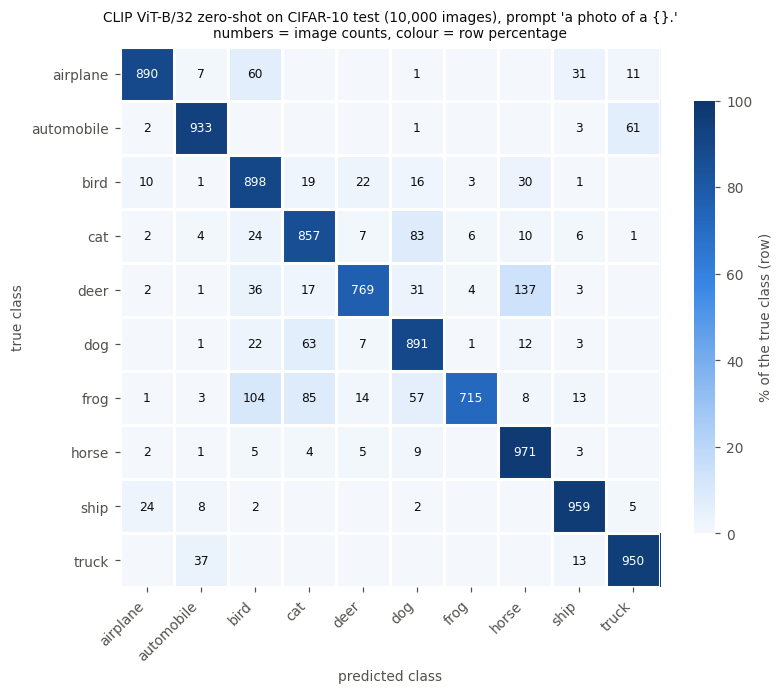

In [22]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)
row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(row_pct, cmap=cmap, vmin=0, vmax=100)
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0:
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=8,
                    color="white" if row_pct[i, j] > 55 else INK)
ax.set_xticks(range(10)); ax.set_xticklabels(cifar_classes, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(cifar_classes)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-.5, 10, 1), minor=True); ax.set_yticks(np.arange(-.5, 10, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("% of the true class (row)", color=INK_2); cb.outline.set_visible(False)
ax.set_title(f"CLIP ViT-B/32 zero-shot on CIFAR-10 test ({n_eval:,} images), prompt 'a photo of a {{}}.'\n"
             f"numbers = image counts, colour = row percentage", fontsize=9)
plt.savefig("figures/part2_confusion_matrix.png", dpi=140)
plt.show()

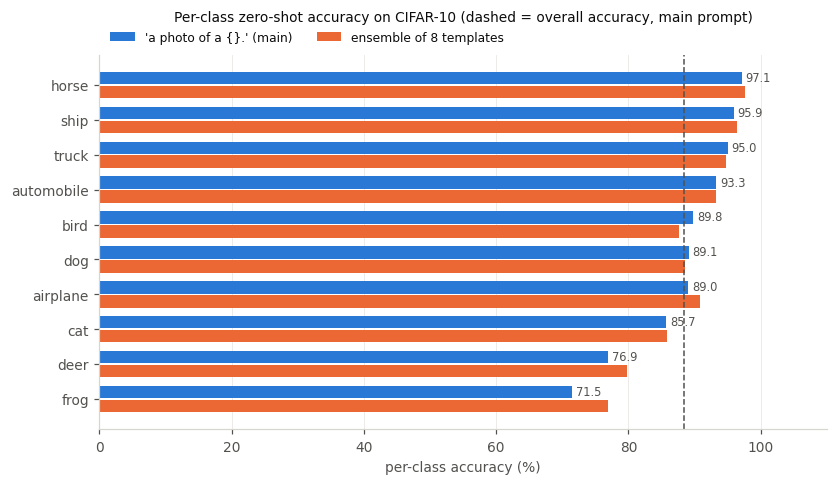

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
srt = per_class_acc.sort_values(MAIN)
y = np.arange(10)
ax.barh(y + 0.2, srt[MAIN], height=0.36, color=BLUE, label="'a photo of a {}.' (main)")
ax.barh(y - 0.2, srt[list(PROMPT_SETS)[2]], height=0.36, color=ORANGE, label=f"ensemble of {len(ENSEMBLE_TEMPLATES)} templates")
for yy, v in zip(y, srt[MAIN]):
    ax.text(v + 0.6, yy + 0.2, f"{v:.1f}", va="center", fontsize=7.5, color=INK_2)
ax.axvline(100 * (predictions[MAIN] == cifar_labels).mean(), color=INK_2, linestyle="--", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(srt.index)
ax.set_xlim(0, 110); ax.set_xticks(range(0, 101, 20)); ax.set_xlabel("per-class accuracy (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8)
ax.set_title("Per-class zero-shot accuracy on CIFAR-10 (dashed = overall accuracy, main prompt)", fontsize=9, pad=22)
plt.savefig("figures/part2_per_class_accuracy.png", dpi=140)
plt.show()

### Which classes get confused, and what do the mistakes look like?

Most common mistakes (main prompt):
      true predicted as  images  % of true class
      deer        horse     137             13.7
      frog         bird     104             10.4
      frog          cat      85              8.5
       cat          dog      83              8.3
       dog          cat      63              6.3
automobile        truck      61              6.1
  airplane         bird      60              6.0
      frog          dog      57              5.7
     truck   automobile      37              3.7
      deer         bird      36              3.6


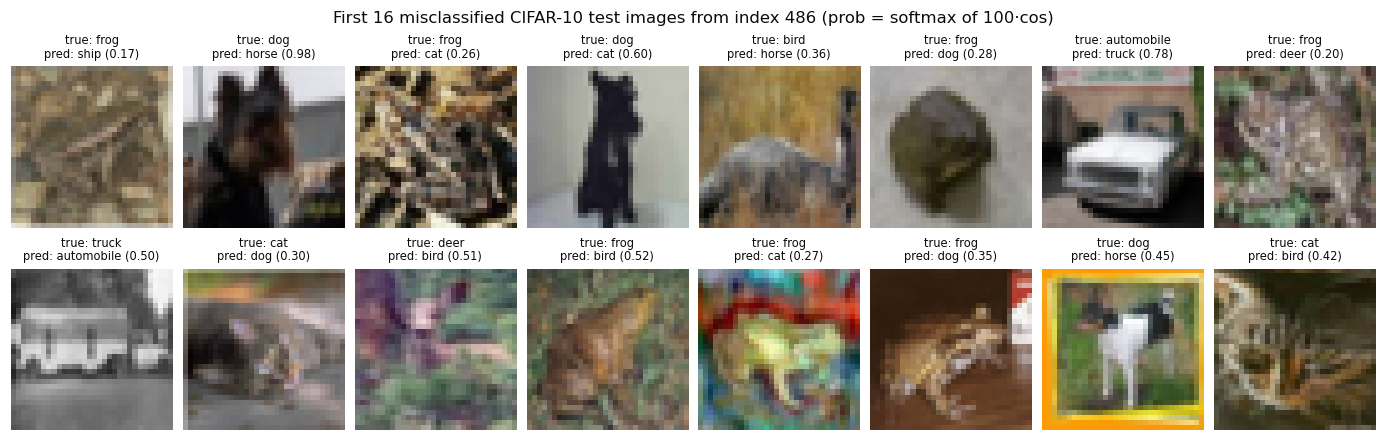


mean top-1 probability: correct predictions 0.875 | wrong predictions 0.534


In [24]:
pairs = [(cifar_classes[i], cifar_classes[j], cm[i, j], 100 * cm[i, j] / cm[i].sum())
         for i in range(10) for j in range(10) if i != j]
top_pairs = pd.DataFrame(pairs, columns=["true", "predicted as", "images", "% of true class"]).sort_values("images", ascending=False)
print("Most common mistakes (main prompt):")
print(top_pairs.head(10).to_string(index=False, float_format=lambda x: f"{x:.1f}"))

# 16 wrong predictions starting at index SLICE, with CLIP's confidence
wrong = [i for i in range(SLICE, n_eval) if predictions[MAIN][i] != cifar_labels[i]][:16] or \
        [i for i in range(n_eval) if predictions[MAIN][i] != cifar_labels[i]][:16]
fig, axes = plt.subplots(2, 8, figsize=(12.5, 3.9))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(cifar[i][0]); ax.axis("off")
    p = predictions[MAIN][i]
    ax.set_title(f"true: {cifar_classes[cifar_labels[i]]}\npred: {cifar_classes[p]} ({probs_main[i, p]:.2f})", fontsize=7.5)
fig.suptitle(f"First 16 misclassified CIFAR-10 test images from index {SLICE} (prob = softmax of 100·cos)")
plt.savefig("figures/part2_misclassified.png", dpi=140)
plt.show()

conf = probs_main.max(axis=1)
right = predictions[MAIN] == cifar_labels
print(f"\nmean top-1 probability: correct predictions {conf[right].mean():.3f} | wrong predictions {conf[~right].mean():.3f}")

In [25]:
# save the numbers behind the tables and figures
part1.to_csv(f"results/part1_similarity_scores{SUFFIX}.csv", index=False)
pd.DataFrame({"index": np.arange(n_eval), "true": [cifar_classes[c] for c in cifar_labels],
              **{f"pred [{n}]": [cifar_classes[c] for c in p] for n, p in predictions.items()},
              "prob main": probs_main.max(axis=1)}).to_csv(f"results/part2_predictions{SUFFIX}.csv", index=False)
metrics = {
    "model": MODEL_NAME, "device": f"{device} ({device_name})", "smoke_test": SMOKE_TEST,
    "part1": {"caption": CAPTION, "target_class": class_names[TARGET], "images": int(len(part1)),
              "images_per_class": N_PER_CLASS, "auc_target_vs_rest": round(float(auc), 4),
              "auc_target_vs_cls_b": round(float(auc_vs_b), 4), "precision_top100": round(float(p_at_100), 4),
              "per_class": json.loads(per_class.round(4).to_json(orient="index")),
              "all_captions": json.loads(caption_table.round(4).to_json(orient="records"))},
    "part2": {"images": int(n_eval), "overall_accuracy": json.loads(overall.round(4).to_json(orient="records")),
              "per_class_accuracy": json.loads(per_class_acc.round(2).to_json(orient="index")),
              "confusion_matrix_main": cm.tolist(), "classes": cifar_classes,
              "top_confusions": json.loads(top_pairs.head(10).round(2).to_json(orient="records")),
              "encode_seconds": None if CIFAR_ENCODE_S is None else round(CIFAR_ENCODE_S, 1)},
    "total_runtime_s": round(time.time() - RUN_START, 1),
}
with open(f"results/hw11_metrics{SUFFIX}.json", "w") as f:
    json.dump(metrics, f, indent=1)
log(f"saved results/hw11_metrics{SUFFIX}.json and the CSV files | total time {(time.time() - RUN_START) / 60:.1f} min")

[2026-11-17T19:15:46Z] saved results/hw11_metrics.json and the CSV files | total time 3.0 min


## 15. Findings for Part 2

**Overall accuracy.** With the prompt `"a photo of a {class}."`, CLIP classifies **8,833 of the 10,000** CIFAR-10 test images correctly (**88.33%**), without seeing a single CIFAR-10 training image. For comparison, the teacher CNN in the distillation demo, trained for 10 epochs on all 50,000 training images, got 73.06%, and random guessing would be 10%. That's what pre-training on 400 million image-text pairs gives you.

**Prompt wording matters a little.** The demo's `"an image of a {}"` got 89.06% and the 8-template ensemble 89.17%, so the "main" prompt was actually the worst of the three, by up to 0.84 points (84 images). The ensemble helped most on the hard classes (frog 71.5 → 76.9%, deer 76.9 → 79.8%), but it made bird worse (89.8 → 87.7%). Averaging prompts like "a blurry / low resolution / pixelated photo of a ..." makes sense for 32×32 images, but the gain is small.

**Per-class accuracy (main prompt) and how often each class is predicted:**

| Class | Accuracy (recall) % | Times predicted | Precision % |
| --- | ---: | ---: | ---: |
| horse | 97.1 | 1,168 | 83.1 |
| ship | 95.9 | 1,035 | 92.7 |
| truck | 95.0 | 1,028 | 92.4 |
| automobile | 93.3 | 996 | 93.7 |
| bird | 89.8 | 1,151 | 78.0 |
| dog | 89.1 | 1,091 | 81.7 |
| airplane | 89.0 | 933 | 95.4 |
| cat | 85.7 | 1,045 | 82.0 |
| deer | 76.9 | 824 | 93.3 |
| frog | 71.5 | 729 | 98.1 |

(Precision comes from the columns of the confusion matrix.) The vehicles and horse are easy. Frog and deer are clearly the hardest. The two numbers often go in opposite directions. CLIP rarely *says* "frog" (729 times for 1,000 frogs), but when it does it's almost always right (98.1%). "Horse" and "bird" are over-predicted (1,168 and 1,151 times), so many images of other animals end up there.

**The confusion matrix shows mostly sensible mistakes:**

- **deer → horse: 137 images (13.7% of all deer)**, the biggest single error. Brown four-legged animal on grass, at 32×32.
- **frog → bird (104), frog → cat (85), frog → dog (57)**: almost 25% of frogs get called another animal. The misclassified examples show why: CIFAR frogs are brownish blobs on textured ground, and some are hard to see even for me.
- **cat ↔ dog (83 and 63)**: the classic pair.
- **automobile → truck (61), truck → automobile (37)**: pickups and vans sit between the two.
- **airplane → bird (60)** and **airplane → ship (31)**: things against a plain sky or water background.

Animals mostly get mixed up with other animals and vehicles with other vehicles. Only 58 of the 6,000 animal images (about 1%) are called a vehicle, and the one big exception the other way is airplane → bird. So the mistakes are about fine details, not about CLIP missing what kind of thing is in the picture.

**Confidence.** The mean top-1 probability (softmax over 100 × cos) is 0.875 for correct predictions and 0.534 for wrong ones, so CLIP is usually less sure when it's wrong. There are still confident mistakes. In the misclassified grid, a small dark dog is called a horse with probability 0.98.

## 16. Limitations and Conclusion

**Limitations**

- **Tiny, low-resolution images.** FashionMNIST is 28×28 grayscale and CIFAR-10 is 32×32, and both are upscaled 7-8× to the 224×224 that CLIP expects. CLIP was trained on normal-sized internet photos, so all the results here are probably worse than CLIP would do on real photos. The shirt-vs-T-shirt problem is partly a resolution problem.
- **Only one caption in Part 1, chosen by my personal parameter.** I added the all-class AUC table to show that "shirt" is one of the harder cases, but each caption still uses one fixed wording ("a photo of a ..."). Other wordings, like "a button-up shirt with a collar", might separate shirts from T-shirts better. I didn't test that.
- **Class names as labels.** FashionMNIST's names are the dataset's own categories ("T-shirt/top" even gives the awkward caption "a photo of a t-shirt/top."), not how people normally describe clothes. That hurts CLIP for the classes whose names overlap.
- **One model.** Only ViT-B/32, the smallest standard CLIP. Larger CLIP models would probably do better, but I didn't try them.
- **100 images per class in Part 1.** The AUCs and top-100 shares are based on 1,000 images and would move a bit with a different SLICE. Part 2 uses the full test set, so its numbers are stable.
- **Small device differences.** The run used Apple's MPS backend. Floating-point results can differ a tiny bit from CUDA or CPU, which could flip a few borderline predictions.

**Conclusion**

CLIP puts images and text in the same 512-d space, so after L2 normalization a dot product directly measures how well a caption matches an image. In Part 1, the caption "a photo of a shirt." ranked the 1,000 FashionMNIST images in a sensible order: upper-body clothes first and shoes last, with AUC 0.840 for Shirt vs. the rest. But it scored T-shirts slightly higher than actual shirts (AUC 0.429 between the two), so the caption captures the general category but not FashionMNIST's fine distinction. In Part 2, the same idea used as a classifier got **88.33%** zero-shot accuracy on the CIFAR-10 test set (89.17% with a prompt ensemble), better than the supervised CNN from the demo (73.06%) without any training. Per class it ranged from 97.1% (horse) to 71.5% (frog). The confusion matrix shows the mistakes are between similar-looking classes: deer → horse, frog → bird/cat, cat ↔ dog, automobile ↔ truck.